# 05 Error analysis

The figures, the most common confusions, confident mistakes and refusals, and the example articles on the desk, all from the deployed system's test predictions. Article titles are quoted, never translated.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Keaane/Ikinyamakuru/blob/main/notebooks/05_error_analysis.ipynb)

In [1]:
# Setup: run from the repository root, on a laptop or on Colab.
import os
import subprocess
import sys
import warnings
from pathlib import Path

if "google.colab" in sys.modules:
    if not Path("/content/Ikinyamakuru").exists():
        subprocess.run(["git", "clone", "-q", "https://github.com/Keaane/Ikinyamakuru.git", "/content/Ikinyamakuru"], check=True)
    os.chdir("/content/Ikinyamakuru")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
elif Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, str(Path("src").resolve()))

# Show each warning as one short line.
warnings.showwarning = lambda message, category, *args, **kwargs: print(f"{category.__name__}: {message}")

In [2]:
import json

import matplotlib.pyplot as plt
import numpy as np

from inkuru.data import load_split, read_jsonl
from inkuru.labels import LABELS
from inkuru.paths import DATA, FIGURES, RESULTS

plt.rcParams.update({
    "font.size": 11, "axes.edgecolor": "#222", "axes.labelcolor": "#222", "xtick.color": "#222",
    "ytick.color": "#222", "text.color": "#222", "figure.facecolor": "white", "axes.facecolor": "white",
})
FIGURES.mkdir(parents=True, exist_ok=True)

metrics = json.loads((RESULTS / "metrics.json").read_text())
winner = metrics["selected"]
threshold = metrics["threshold"]["threshold"]
test_rows = {row["id"]: row for row in load_split("test")}
predictions = read_jsonl(RESULTS / f"{winner}_test.jsonl")

matrix = np.zeros((len(LABELS), len(LABELS)), dtype=int)
index = {label: i for i, label in enumerate(LABELS)}
examples = []
for item in predictions:
    row = test_rows[item["id"]]
    matrix[index[item["gold"]], index[item["pred"]]] += 1
    examples.append({
        "id": item["id"], "title": row["title"], "text": row["text"], "gold": item["gold"], "pred": item["pred"],
        "confidence": item["confidence"], "top": item["top"], "correct": item["gold"] == item["pred"],
        "filed": item["confidence"] >= threshold,
    })
print(f"{winner}: {len(examples):,} test articles, cutoff {threshold}")

char_balanced: 3,464 test articles, cutoff 0.5743


## Macro-F1 for every system

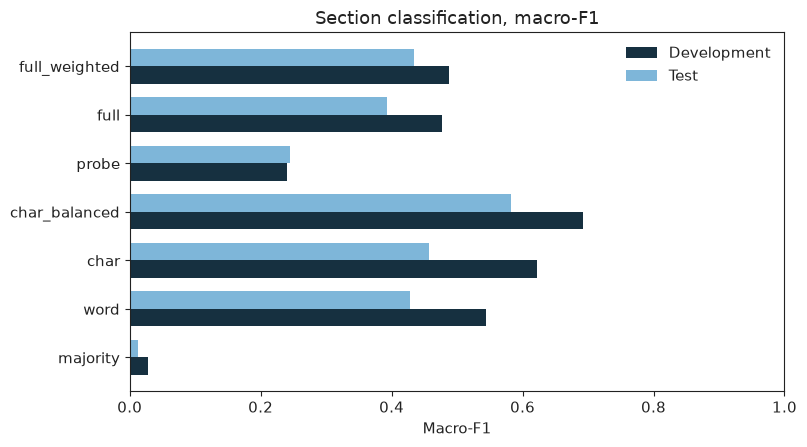

In [3]:
names = list(metrics["systems"])
y = np.arange(len(names))
fig, ax = plt.subplots(figsize=(8.2, 4.6))
ax.barh(y - 0.18, [metrics["systems"][n]["dev"]["macro_f1"] for n in names], height=0.36, color="#163040", label="Development")
ax.barh(y + 0.18, [metrics["systems"][n]["test"]["macro_f1"] for n in names], height=0.36, color="#7eb6d9", label="Test")
ax.set_yticks(y, names)
ax.set_xlabel("Macro-F1")
ax.set_xlim(0, 1)
ax.legend(frameon=False)
ax.set_title("Section classification, macro-F1")
fig.tight_layout()
fig.savefig(FIGURES / "macro_f1.png", dpi=160)
plt.show()

## Test F1 by section and the confusion matrix

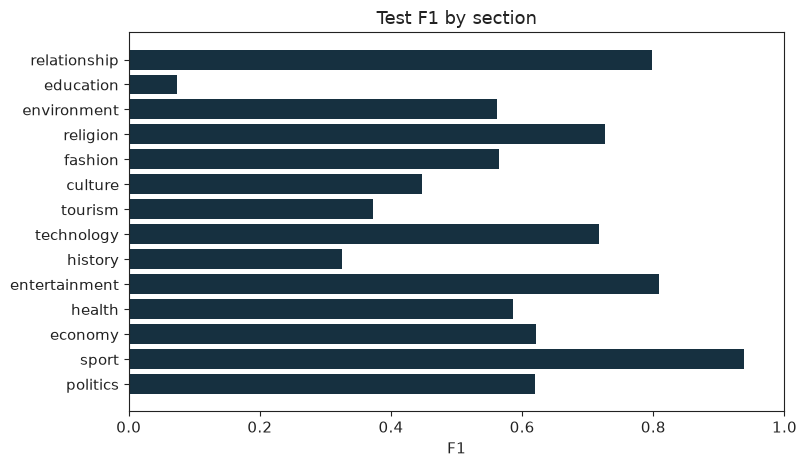

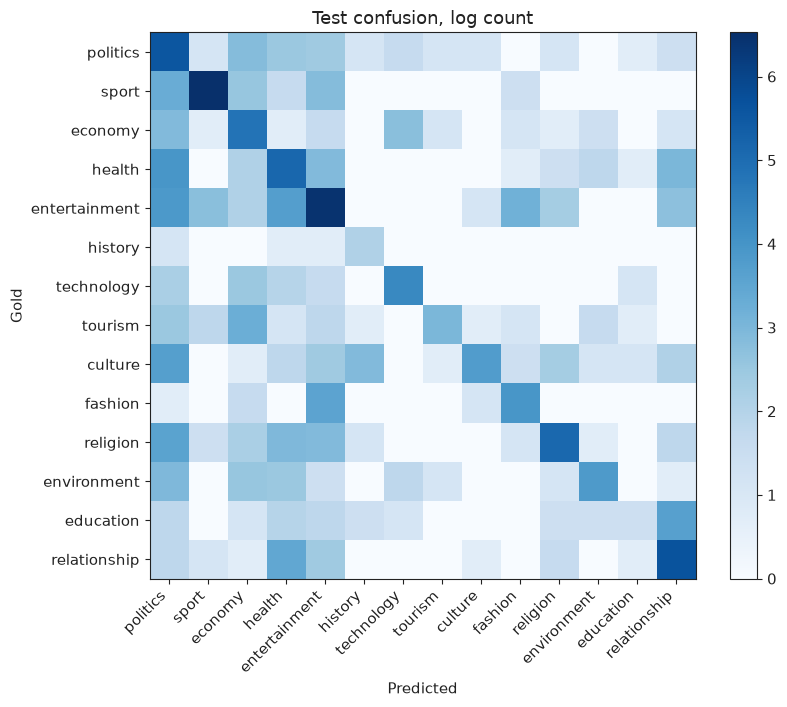

most common confusions:
   health filed as politics: 50
   entertainment filed as politics: 47
   entertainment filed as health: 40
   culture filed as politics: 39
   education filed as relationship: 38
   religion filed as politics: 35
   fashion filed as entertainment: 34
   relationship filed as health: 31


In [4]:
per_class = metrics["systems"][winner]["per_class"]
fig, ax = plt.subplots(figsize=(8.2, 4.8))
ax.barh(list(LABELS), [per_class[label]["f1"] for label in LABELS], color="#163040")
ax.set_xlim(0, 1)
ax.set_xlabel("F1")
ax.set_title("Test F1 by section")
fig.tight_layout()
fig.savefig(FIGURES / "per_class_f1.png", dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(8.4, 7.2))
image = ax.imshow(np.log1p(matrix), cmap="Blues")
ax.set_xticks(range(len(LABELS)), LABELS, rotation=45, ha="right")
ax.set_yticks(range(len(LABELS)), LABELS)
ax.set_xlabel("Predicted")
ax.set_ylabel("Gold")
ax.set_title("Test confusion, log count")
fig.colorbar(image, ax=ax, fraction=0.046)
fig.tight_layout()
fig.savefig(FIGURES / "confusion.png", dpi=160)
plt.show()

pairs = []
for gold_i, gold in enumerate(LABELS):
    for pred_i, pred in enumerate(LABELS):
        if gold_i != pred_i and matrix[gold_i, pred_i] > 0:
            pairs.append({"gold": gold, "pred": pred, "n": int(matrix[gold_i, pred_i])})
pairs.sort(key=lambda item: item["n"], reverse=True)
print("most common confusions:")
for pair in pairs[:8]:
    print(f"   {pair['gold']} filed as {pair['pred']}: {pair['n']}")

## Confidence and the cutoff

Correct filings tend to score higher than wrong ones, but the two overlap, so the cutoff holds back some correct filings along with the errors.

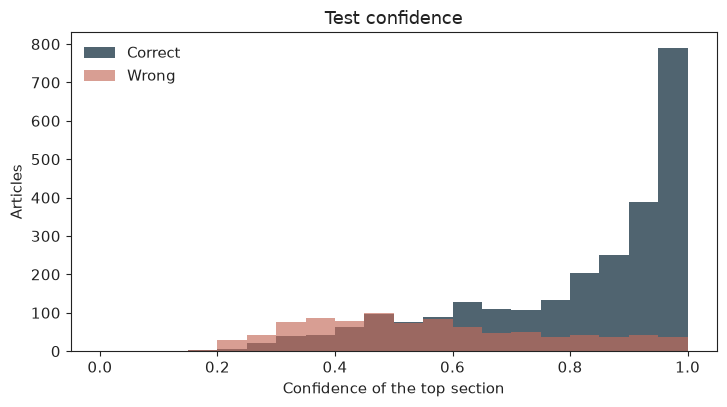

In [5]:
fig, ax = plt.subplots(figsize=(7.4, 4.2))
bins = np.linspace(0, 1, 21)
ax.hist([item["confidence"] for item in examples if item["correct"]], bins=bins, alpha=0.75, color="#163040", label="Correct")
ax.hist([item["confidence"] for item in examples if not item["correct"]], bins=bins, alpha=0.65, color="#c46b5a", label="Wrong")
ax.set_xlabel("Confidence of the top section")
ax.set_ylabel("Articles")
ax.legend(frameon=False)
ax.set_title("Test confidence")
fig.tight_layout()
fig.savefig(FIGURES / "confidence.png", dpi=160)
plt.show()

## Confident mistakes, correct filings, and refusals

In [6]:
confident_errors = sorted((e for e in examples if not e["correct"] and e["filed"]), key=lambda e: e["confidence"], reverse=True)
correct = sorted((e for e in examples if e["correct"] and e["filed"]), key=lambda e: e["confidence"], reverse=True)
refused = sorted((e for e in examples if not e["filed"]), key=lambda e: e["confidence"])

for heading, items in (("confident mistakes", confident_errors[:8]), ("correct filings", correct[:6]), ("lowest refusals", refused[:3])):
    print(heading + ":")
    for item in items:
        print(f"   gold {item['gold']:13s} predicted {item['pred']:13s} {item['confidence']:.2f}  \"{item['title'][:80]}\"")
    print()

confident mistakes:
   gold entertainment predicted fashion       1.00  "Miss Supranational 2016:Nyampinga Akiwacu   yatangaje ko  yishimiye kuba yarahes"
   gold entertainment predicted fashion       1.00  "Uwase wahagarariye u Rwanda muri Miss Supranational 2018 yitabiriye irindi rusha"
   gold entertainment predicted fashion       1.00  "Umwiraburakazi wo muri Afurika y’Epfo niwe wegukanye ikamba rya Miss Universe (A"
   gold entertainment predicted fashion       1.00  "Miss Uwase  yiyerekanye mu cyiciro gikomeye cyo kwerekana imiterere y’umubiri [ "
   gold entertainment predicted religion      1.00  "Shekinah Worship Team Masoro yamuritse album mu gitaramo cyamaze amasaha 12"
   gold entertainment predicted sport         1.00  "Umutoza Mashami Vincent yaretse umuryango abakinnyi 5 mu Mavubi yitegura guhanga"
   gold entertainment predicted sport         1.00  "Intego za APR Fc ni ukurenga aho Rayon Sports yageze-Mugiraneza Migy"
   gold culture       predicted religion      1.00  

## Desk examples and the error notes

Four correct filings from different sections, two confident mistakes, one refusal, and one article from the rarest test section become the example buttons on the desk.

In [7]:
used, buttons = set(), []


def take(pool, note, limit, require_label=None):
    got = 0
    for item in pool:
        if item["id"] in used or (require_label and item["gold"] != require_label):
            continue
        if not item["title"] or len(item["title"]) < 12:
            continue
        used.add(item["id"])
        buttons.append({**item, "note": note})
        got += 1
        if got >= limit:
            break


seen_labels = set()
for item in correct:
    if item["gold"] in seen_labels or item["id"] in used or len(item["title"]) < 12:
        continue
    seen_labels.add(item["gold"])
    used.add(item["id"])
    buttons.append({**item, "note": "correct"})
    if len(seen_labels) == 4:
        break
take(confident_errors, "confident error", 2)
take(refused, "refused", 1)
rare = min(LABELS, key=lambda label: per_class[label]["support"])
take(correct + confident_errors + refused, "rare section", 1, require_label=rare)

(DATA / "ui_examples.json").write_text(json.dumps(
    [{"title": item["title"], "text": item["text"][:6000]} for item in buttons], ensure_ascii=False, indent=2) + "\n")


def brief(item):
    return {"title": item["title"], "gold": item["gold"], "pred": item["pred"],
            "confidence": round(item["confidence"], 4), "filed": item["filed"], "note": item.get("note")}


report = {
    "winner": winner,
    "threshold": threshold,
    "top_confusions": pairs[:12],
    "confident_errors": [brief({**item, "note": "error"}) for item in confident_errors[:8]],
    "correct_examples": [brief({**item, "note": "correct"}) for item in correct[:6]],
    "refused_example": brief({**refused[0], "note": "refused"}) if refused else None,
    "buttons": [brief(item) for item in buttons],
    "rare_section": rare,
}
(RESULTS / "error_analysis.json").write_text(json.dumps(report, ensure_ascii=False, indent=2) + "\n")
for item in buttons:
    print(f"{item['note']:16s} {item['gold']:13s} -> {item['pred']:13s} {item['confidence']:.2f}  \"{item['title'][:70]}\"")

correct          culture       -> culture       1.00  "Menya zimwe mu nyito zihariye z’inka n’amata mu muco wa Kinyarwanda"
correct          fashion       -> fashion       1.00  "Abanyarwanda bacanye umucyo muri Tokyo Africa Collections (Amafoto)"
correct          environment   -> environment   1.00  "Icyo REMA isaba abaturage mu bihe by’imvura n’ibiza"
correct          entertainment -> entertainment 1.00  "Indirimbo yanjye na Meddy irahari ariko ntabwo irarangira-Diamond Plat"
confident error  entertainment -> fashion       1.00  "Miss Supranational 2016:Nyampinga Akiwacu   yatangaje ko  yishimiye ku"
confident error  entertainment -> fashion       1.00  "Uwase wahagarariye u Rwanda muri Miss Supranational 2018 yitabiriye ir"
refused          health        -> entertainment 0.17  "Umuyapani yabaye umusare (navigateur) wa mbere ufite ubumuga bwo kutab"
rare section     history       -> history       0.89  "#KWIBUKA 26  : Tariki 9 Mata 1994  Abasirikare ba Leta ya Habyarimana "


## Near repeats across the splits

Notebook 01 removes exact repeats only. This counts test articles that open with the same 300 characters of body text as a training article, or share a title of at least 15 characters with one, and the openings that repeat inside the test file. It also counts Cloudflare's `[email protected]` placeholder, a trace of how some publishers' pages were scraped ([data/README.md](../data/README.md#known-limits)).

In [8]:
from collections import defaultdict

from inkuru.data import normalize

splits = {name: load_split(name) for name in ("train", "dev", "test")}
keys = {
    "opening": lambda row: normalize(row["content"])[:300] if len(normalize(row["content"])) >= 300 else None,
    "title": lambda row: normalize(row["title"]) if len(row["title"]) >= 15 else None,
}
for kind, key in keys.items():
    index = {name: defaultdict(list) for name in splits}
    for name, rows in splits.items():
        for row in rows:
            if (value := key(row)) is not None:
                index[name][value].append(row)
    shared = set(index["train"]) & set(index["test"])
    matched = [row for value in shared for row in index["test"][value]]
    relabelled = sum(any(other["label"] != row["label"] for other in index["train"][value])
                     for value in shared for row in index["test"][value])
    inside = sum(len(rows) > 1 for rows in index["test"].values())
    print(f"{kind}: {len(matched)} test articles match a training article ({relabelled} under a different label), "
          f"{inside} repeat inside the test file")
placeholder = "[email\xa0protected]"  # Cloudflare writes a non-breaking space
print("email placeholder:", {name: sum(placeholder in row["text"] for row in rows) for name, rows in splits.items()})

opening: 15 test articles match a training article (3 under a different label), 30 repeat inside the test file
title: 20 test articles match a training article (5 under a different label), 9 repeat inside the test file
email placeholder: {'train': 1, 'dev': 0, 'test': 60}
